# Applying the fixed Savitzky–Golay filter to a quantum wave function

The released version of `scipy.signal.savgol_filter` discards the imaginary
part of complex input. I fixed this in
[pull request #26784](https://github.com/scipy/scipy/pull/26784), so that the
filter now smooths complex signals and estimates their derivatives just as it
does for real ones. This notebook uses the fixed version on a physical
example where complex numbers are essential: a quantum wave function.

In [3]:
import sys
sys.path.insert(0, "/Users/gl/scipy/build-install/usr/lib/python3.15/site-packages")

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.signal import savgol_filter

print("SciPy version:", scipy.__version__)
print("SciPy location:", scipy.__file__)

z = np.exp(1j * np.linspace(0, 1, 11))
print("Complex input kept:", np.iscomplexobj(savgol_filter(z, 5, 2)))

SciPy version: 2.0.0.dev0+git20261122.7e22ea2
SciPy location: /Users/gl/scipy/build-install/usr/lib/python3.15/site-packages/scipy/__init__.py
Complex input kept: True


## Measuring a wave function

A wave function $\Psi(x)$ is complex, and for a long time it was thought that
it could only be reconstructed indirectly. Lundeen et al.
([arXiv:1112.3575](https://arxiv.org/abs/1112.3575)) showed instead that it can
be measured directly: their experiment gives the real and imaginary parts of
$\Psi$ at a chosen point, and by repeating it across positions they obtained
$\Psi(x)$ point by point on an evenly spaced grid. Each value is an average
over many identically prepared systems, so the measured samples are noisy.
The experiment itself was done on the transverse wave function of a photon,
but the authors argue that the method is general and can be applied to other
degrees of freedom and other quantum systems.

Measurements like these produce noisy samples of the real and imaginary parts
of $\Psi(x)$ at evenly spaced points. This is the kind of data the
Savitzky–Golay filter is designed for. It can smooth the samples and estimate
the derivatives of $\Psi$, and quantities such as momentum and kinetic energy
can then be computed from those derivatives.

In this notebook I simulate such data from a wave function whose exact form is
known: the Gaussian wave packet. The simulation has no physical
use in itself, since the exact wave function is already known. What it does
is let us compare what the filter recovers with the true values. In a real
measurement there would be no exact answer to compare against, and that is
where the filter would be useful.

## Simulating a measured wave function

As a test case we take a wave function whose exact form we know: a Gaussian
packet with a phase that has both a linear and a quadratic part,

$$\Psi(x) = A\, e^{-x^2/4\sigma^2}\, e^{i(k_0 x + \beta x^2)},$$

where $\sigma$ sets the width of the packet, $k_0$ gives it momentum, and
$\beta$ makes the phase vary non-linearly across it. $A = (2\pi\sigma^2)^{-1/4}$ normalizes it. We work in
units where $\hbar = m = 1$ and use $\sigma = 1$, $k_0 = 5$ and $\beta = 0.5$.

To imitate a direct measurement like the one in the paper, we sample the real
and the imaginary parts of $\Psi$ at 241 evenly spaced positions between
$x = -6$ and $x = 6$ (a spacing of $0.05$), and add independent Gaussian noise
with standard deviation $0.02$ to each of them, since in the experiment they
are measured as two separate quantities. The plot compares these noisy samples
with the exact wave function.

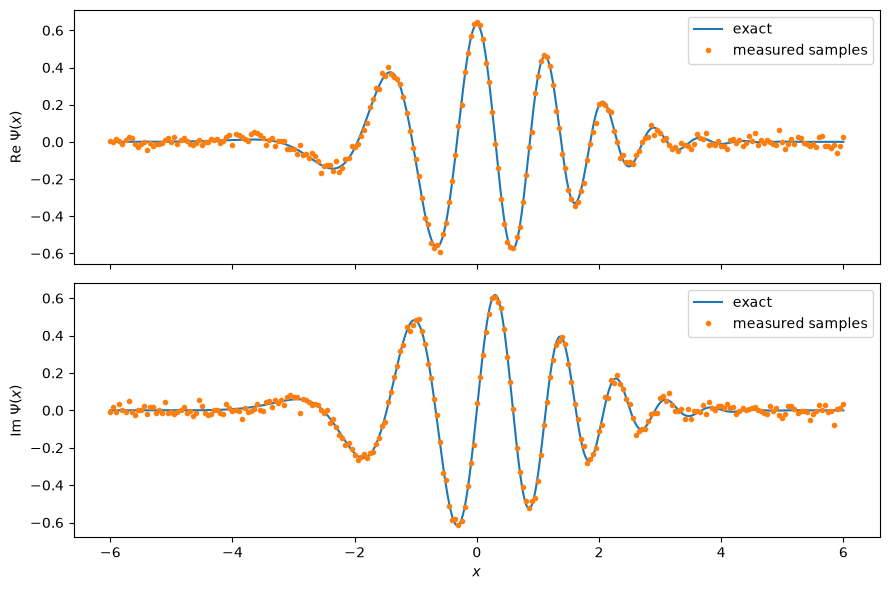

In [4]:
# Units with hbar = m = 1
sigma = 1.0   # width of the packet
k0 = 5.0      # central wave number (sets the momentum)
beta = 0.5    # strength of the quadratic phase
A = (2 * np.pi * sigma**2) ** (-0.25)   # normalization


def psi_exact(x):
    """Gaussian wave function with a linear and a quadratic phase."""
    return A * np.exp(-x**2 / (4 * sigma**2)) * np.exp(1j * (k0 * x + beta * x**2))


# "Measured" samples: evenly spaced positions, with independent noise
# on the real and imaginary parts
rng = np.random.default_rng(0)
x = np.linspace(-6, 6, 241)
dx = x[1] - x[0]
noise = 0.02
psi_noisy = psi_exact(x) + noise * (rng.standard_normal(x.size)
                                    + 1j * rng.standard_normal(x.size))

# Plot the samples against the exact wave function
x_fine = np.linspace(-6, 6, 2000)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(x_fine, psi_exact(x_fine).real, label="exact")
axes[0].plot(x, psi_noisy.real, "o", ms=3, label="measured samples")
axes[0].set_ylabel(r"Re $\Psi(x)$")
axes[0].legend(loc="upper right")

axes[1].plot(x_fine, psi_exact(x_fine).imag, label="exact")
axes[1].plot(x, psi_noisy.imag, "o", ms=3, label="measured samples")
axes[1].set_ylabel(r"Im $\Psi(x)$")
axes[1].set_xlabel("$x$")
axes[1].legend(loc="upper right")

fig.tight_layout()
plt.show()

## Filtering the measured wave function

We now apply `savgol_filter` directly to the complex samples. With the fix, the
filter smooths the real and the imaginary parts together, so there is no need
to split $\Psi$ into two real signals and filter them separately.

Each filtered point comes from a polynomial fitted by least squares to the
samples in a window around it. We use a window of 21 samples and a polynomial of degree 6. The window has to be short compared with one oscillation of $\Psi$, and the degree high enough for the polynomial to follow it: a longer window or a lower degree would remove more noise, but would
also start to flatten the peaks. The plot compares the filtered points with the
exact wave function.

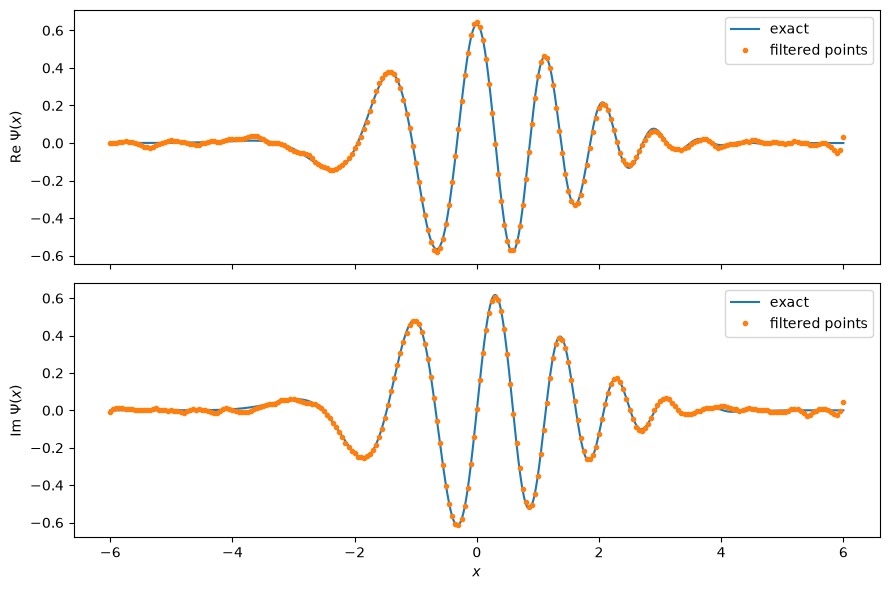

In [5]:
window_length = 21
polyorder = 6

psi_smooth = savgol_filter(psi_noisy, window_length, polyorder)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(x_fine, psi_exact(x_fine).real, label="exact")
axes[0].plot(x, psi_smooth.real, "o", ms=3, label="filtered points")
axes[0].set_ylabel(r"Re $\Psi(x)$")
axes[0].legend(loc="upper right")

axes[1].plot(x_fine, psi_exact(x_fine).imag, label="exact")
axes[1].plot(x, psi_smooth.imag, "o", ms=3, label="filtered points")
axes[1].set_ylabel(r"Im $\Psi(x)$")
axes[1].set_xlabel("$x$")
axes[1].legend(loc="upper right")

fig.tight_layout()
plt.show()

## The momentum

The expectation value of the momentum is

$$\langle p \rangle = \int_{-\infty}^{\infty} \Psi^*(x)\left(-i\hbar\,\frac{\partial \Psi}{\partial x}\right)dx .$$

Differentiating
$\Psi(x) = A\, e^{-x^2/4\sigma^2}\, e^{i(k_0 x + \beta x^2)}$
gives

$$\frac{\partial \Psi}{\partial x} = \Psi(x)\left[-\frac{x}{2\sigma^2} + i\,(k_0 + 2\beta x)\right],$$

where the real term comes from the Gaussian envelope and the imaginary term
from the phase. Since $\Psi^*\Psi = |\Psi|^2$, the integral becomes

$$\langle p \rangle = -i\hbar \int |\Psi(x)|^2 \left[-\frac{x}{2\sigma^2} + i\,(k_0 + 2\beta x)\right] dx .$$

Here $|\Psi(x)|^2 = A^2 e^{-x^2/2\sigma^2}$ is a normalized Gaussian centred at
$x = 0$, so $\int |\Psi|^2\,dx = 1$ and $\int x\,|\Psi|^2\,dx = 0$. The two
terms proportional to $x$ therefore vanish, and only $k_0$ is left:

$$\langle p \rangle = -i\hbar \cdot i k_0 = \hbar k_0 = 5 .$$

## Estimating the momentum with the filter

To compute $\langle p \rangle$ from the measured samples we need the
derivative $\partial\Psi/\partial x$. Differentiating the noisy samples
directly would amplify the noise, so instead we let the filter estimate it:
with `deriv=1`, `savgol_filter` returns the derivative of the polynomial fitted
in each window rather than its value. The argument `delta` is the spacing
between the samples, so that the derivative is taken with respect to $x$. We
use the same window and degree as for the smoothing.

We then compute

$$\langle p \rangle = \int \Psi^*(x)\left(-i\hbar\,\frac{\partial \Psi}{\partial x}\right)dx .$$

Since we only know the integrand at the sample points, we approximate the
integral with the trapezoidal rule: at each point we evaluate the integrand
using the filtered values of $\Psi$ and $\partial\Psi/\partial x$, join
neighbouring points with straight lines, and add up the areas of the
trapezoids underneath. We compare the result with the exact value
$\hbar k_0 = 5$. The exact $\langle p \rangle$ is real, so we keep the real
part of the estimate; the small imaginary part that the noise leaves is close
to zero.

In [12]:
from scipy.integrate import trapezoid

hbar = 1.0

# Estimate the derivative of Psi from the noisy samples
dpsi_smooth = savgol_filter(psi_noisy, window_length, polyorder,
                            deriv=1, delta=dx)

# <p> = integral of Psi* (-i hbar dPsi/dx) dx
p_estimate = trapezoid(np.conj(psi_smooth) * (-1j * hbar) * dpsi_smooth, x)
p_exact = hbar * k0

print(f"Estimated <p>: {p_estimate.real:.3f}")
print(f"Exact <p>:     {p_exact:.3f}")

Estimated <p>: 4.944
Exact <p>:     5.000


## The exact kinetic energy

We want to compute the kinetic energy of the particle:

$$\langle T \rangle = -\frac{\hbar^2}{2m}\int_{-\infty}^{\infty} \Psi^*(x)\,\frac{\partial^2 \Psi}{\partial x^2}\,dx .$$

To compute it by hand it is easier to integrate by parts once, taking
$u = \Psi^*$ and $v' = \partial^2\Psi/\partial x^2$:

$$\int_{-\infty}^{\infty} \Psi^*\,\frac{\partial^2 \Psi}{\partial x^2}\,dx
= \Big[\Psi^*\,\frac{\partial \Psi}{\partial x}\Big]_{-\infty}^{\infty}
- \int_{-\infty}^{\infty} \frac{\partial \Psi^*}{\partial x}\,\frac{\partial \Psi}{\partial x}\,dx .$$

The boundary term vanishes, because $\Psi$ and its derivative go to zero as
$x \to \pm\infty$, as they must for any normalizable wave function. In the
remaining integral, the derivative of the conjugate is the conjugate of the
derivative, so the integrand is $|\partial\Psi/\partial x|^2$. Putting this
back, the two minus signs cancel and

$$\langle T \rangle = \frac{\hbar^2}{2m}\int_{-\infty}^{\infty} \left|\frac{\partial \Psi}{\partial x}\right|^2 dx ,$$

which only needs the first derivative, and also shows that the kinetic energy
can never be negative.

From before,
$\partial\Psi/\partial x = \Psi(x)\left[-\frac{x}{2\sigma^2} + i\,(k_0 + 2\beta x)\right]$,
so

$$\left|\frac{\partial \Psi}{\partial x}\right|^2 = |\Psi(x)|^2\left[\frac{x^2}{4\sigma^4} + (k_0 + 2\beta x)^2\right]
= |\Psi(x)|^2\left[\frac{x^2}{4\sigma^4} + k_0^2 + 4\beta k_0 x + 4\beta^2 x^2\right].$$

$|\Psi|^2$ is a normalized Gaussian centred at $0$ with variance $\sigma^2$, so
$\int |\Psi|^2\,dx = 1$, $\int x\,|\Psi|^2\,dx = 0$ and
$\int x^2\,|\Psi|^2\,dx = \sigma^2$. Therefore

$$\langle T \rangle = \frac{\hbar^2}{2m}\left[k_0^2 + \frac{1}{4\sigma^2} + 4\beta^2\sigma^2\right]
= \frac{1}{2}\left[25 + 0.25 + 1\right] = 13.125 .$$


## Estimating the kinetic energy with the filter

For the kinetic energy we need the second derivative $\partial^2\Psi/\partial x^2$.
We estimate it in the same way as the first: with `deriv=2`, `savgol_filter`
returns the second derivative of the polynomial fitted in each window, and
`delta` again sets the spacing between the samples. We keep the same window
and degree as before.

We then compute

$$\langle T \rangle = -\frac{\hbar^2}{2m}\int \Psi^*(x)\,\frac{\partial^2 \Psi}{\partial x^2}\,dx$$

with the trapezoidal rule, using the filtered values of $\Psi$ and of its
second derivative at each sample point, and compare the result with the exact
value $13.125$. As for the momentum, we keep the real part of the estimate.
The leftover imaginary part is a little larger here, since a second derivative
is more sensitive to noise than a first one, but it is still small compared
with the result.

In [10]:
m = 1.0

# Estimate the second derivative of Psi from the noisy samples
d2psi_smooth = savgol_filter(psi_noisy, window_length, polyorder,
                             deriv=2, delta=dx)

# <T> = -(hbar^2 / 2m) * integral of Psi* d2Psi/dx2 dx
T_estimate = trapezoid(np.conj(psi_smooth) * (-hbar**2 / (2 * m)) * d2psi_smooth, x)
T_exact = hbar**2 / (2 * m) * (k0**2 + 1 / (4 * sigma**2) + 4 * beta**2 * sigma**2)

print(f"Estimated <T>: {T_estimate.real:.3f}")
print(f"Exact <T>:     {T_exact:.3f}")

Estimated <T>: 13.058
Exact <T>:     13.125


## Conclusion

With the fix, `savgol_filter` can be applied directly to complex data such as
a sampled wave function. From noisy samples of $\Psi$, it gave
$\langle p \rangle \approx 4.94$ against the exact value $5$, and
$\langle T \rangle \approx 13.06$ against $13.125$: both within about 1%.
The released version would have discarded the imaginary part of $\Psi$,
which carries all of the momentum, and would have given
$\langle p \rangle = 0$.

How close the estimates come depends on the noise and on the choice of window
and degree, which here could be checked against the exact values. In a real
measurement, like the one by Lundeen et al., there would be no exact values to
compare with, and the filter would be a way to obtain the derivatives of
$\Psi$, and the quantities that depend on them, from the measured samples.